In [ ]:
🧩 First, What Is SVM At All?
Imagine you have two types of points on a piece of paper:

🔴 Red dots (spam emails)

🔵 Blue dots (not spam)

You want to draw one straight line that separates them.

text
🔴 🔴 🔴
🔴 🔴        ← draw a line here
🔵 🔵 🔵
🔵 🔵 🔵
SVM (Support Vector Machine) = a method that finds the best possible line to separate two groups.

But "best" means something specific: SVM wants the line that has the widest possible empty space (margin) on both sides.

text
🔴 🔴 🔴
🔴 🔴
--------- ← top edge of margin
         ← empty "buffer zone"
--------- ← the actual line
         ← empty "buffer zone"
--------- ← bottom edge of margin
🔵 🔵 🔵
🔵 🔵 🔵
That empty buffer zone is called the margin. The wider it is, the more confident the model is.

🧱 Hard Margin SVM (The Strict Version)
Hard Margin says:

"NO point is allowed inside the margin. NO point is allowed to be on the wrong side. Zero mistakes."

text
🔴 🔴 🔴
🔴 🔴
=================  ← margin boundary
    (nothing here)
----------------- ← decision line
    (nothing here)
=================  ← margin boundary
🔵 🔵 🔵
🔵 🔵 🔵
Perfect. Clean. Mathematically beautiful.

❌ But it fails in the real world:
Problem 1 — One outlier ruins everything

text
🔴 🔴 🔴
🔴 🔴         🔴 ← this red dot is way over near the blue side (noise!)
=================
-----------------
=================
🔵 🔵 🔵
🔵 🔵 🔵
To keep that one weird red dot on the correct side, the line has to tilt dramatically. Now it misclassifies actual blue dots. One bad data point destroyed the whole model.

Problem 2 — Overlapping classes = no solution at all

text
🔴 🔵 🔴
🔵 🔴 🔵   ← reds and blues are mixed together
🔵 🔴 🔵
There is no straight line that can perfectly separate them. Hard Margin SVM just... gives up. The math has no answer.

🧸 Soft Margin SVM (The Relaxed Version)
Soft Margin says:

"Look, real data is messy. Let's allow a few mistakes, as long as the overall line is still good."

So it relaxes the rules. It allows:

Some points to sit inside the margin 🟡

Even a few points to be on the wrong side ❌

In exchange, it gets a simpler, more sensible line that works better on new data.

text
🔴 🔴 🔴
🔴 🟡        ← 🟡 allowed inside margin
=================
----------------- ← line is calm and straight now
=================
🔵 🔵 🔵
🔵 🔵 🔵
That 🟡 dot is a "violation" — but the model tolerates it because the overall boundary is much better.

🎚️ The C Parameter — The "Strictness Dial"
This is the single most important knob. Think of C as a strictness dial:

C Value	Behavior	Analogy
High C (e.g., 100)	Very strict. Barely tolerates any mistakes.	A perfectionist teacher
Low C (e.g., 0.1)	Very relaxed. Tolerates many mistakes for a smoother line.	A chill teacher
High C → tries hard to classify every single point correctly → overfits (memorizes noise)

Low C → ignores outliers, focuses on the big picture → underfits if too low

Sweet spot: somewhere in the middle (like C=1.0).

🧠 Mental Model:
High C = "I will contort the line to fit every weird dot"

Low C = "I'd rather have a simple line and ignore weird dots"

🎯 Why Do We Need Soft Margin SVM?
Three big reasons:

Real data is noisy — there are always weird, mislabeled, or outlier points

Real data overlaps — classes aren't perfectly clean in reality

Hard Margin often has no solution — Soft Margin always finds an answer

📊 When Should You Use It?
Use Soft Margin SVM when:

Situation	Why SVM shines
Text classification (spam, sentiment, ticket routing)	Works great in high-dimensional space (many words = many features)
Small-to-medium datasets (hundreds to tens of thousands)	Fast enough; doesn't need millions of rows
Sparse data (bag-of-words, TF-IDF)	Naturally handles lots of zeros
You need a clean geometric boundary	SVM gives you a clear line/plane, not fuzzy rules

Don't use it when:

You have millions of rows (too slow — training is O(n²) to O(n³))

You need probability outputs (SVM gives raw scores, not well-calibrated probabilities)

Your data is pure tabular with feature interactions (XGBoost usually wins there)

⚔️ SVM vs. Other Models — Why Not Just Use X?
Model	What It Does	Why SVM Might Beat It
Logistic Regression	Draws a line considering ALL points equally	SVM only cares about points near the boundary (support vectors) → more robust to far-away noise
Random Forest	Cuts space into boxy regions	RF makes jagged, axis-aligned cuts; SVM makes smooth planes → better for text/high-dim
XGBoost	Great on tabular data with mixed features	XGB overfits on small, sparse, high-dimensional data; SVM handles it gracefully
Rule of thumb:

Tabular data with mixed numeric/categorical features → XGBoost

Text / high-dimensional sparse data with few samples → SVM

Need probabilities + interpretability → Logistic Regression

📦 What You Actually Get Out of SVM
When you train a Soft Margin SVM, you get:

A decision boundary (line/plane/hyperplane) — the separator

Support vectors — the only points that define the boundary (everything else is irrelevant!)

A robust classifier that generalizes to new data

A hard class prediction (not a probability, unless you specifically ask for it)

Fun fact: you could delete 95% of your training data and the model wouldn't change — as long as you keep the support vectors. That's how efficient SVM is.

🍕 One-Sentence Summary
Soft Margin SVM = "Draw the widest possible line between two classes, but forgive a few messy points so the line stays simple and works well on new data."

from sklearn.svm import SVC

# C = strictness dial
model = SVC(kernel='linear', C=1.0)   # 1.0 = balanced
model.fit(X_train, y_train)

# These are the ONLY points that define the boundary:
print(len(model.support_vectors_))
Change C:

C=0.01 → very forgiving, wide margin

C=1000 → very strict, tries to fit everything



                  Soft Margin SVM — Full Working Models for Each Dataset Type 🛠️

Spam Classification (email → spam/ham)

Sentiment Analysis (review → positive/negative)

Ticket Routing (support ticket → category)

Sparse Data (bag-of-words / TF-IDF demonstration)

🧠 First — Why SVM Works for Text
Text data has a unique property:

Each unique word = one feature (dimension)

A document with 5,000 unique words across your vocabulary = 5,000-dimensional space

Most documents only use ~100 of those 5,000 words → most values are 0 → sparse

SVM is uniquely good at this because:

It works in high-dimensional space without needing tons of data

It only cares about support vectors (the tricky boundary cases), not every point

It handles sparse matrices efficiently

In [ ]:
# ==========================================
# SPAM CLASSIFICATION WITH SOFT MARGIN SVM
# ==========================================
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score

# --- STEP 1: DATA ---
emails = [
    "Win a free iPhone now click this link",
    "Congratulations you won a lottery claim your prize",
    "Limited time offer buy now discount 90%",
    "Get rich quick work from home easy money",
    "Free crypto tokens claim now urgent",
    "Meeting scheduled for tomorrow at 10am",
    "Please find the attached report for Q3",
    "Can you review the pull request I submitted",
    "Lunch tomorrow at the usual place",
    "Project deadline extended to next Friday",
    "Reminder: submit your timesheet by EOD",
    "Let's sync up on the client presentation"
]
labels = [
    "spam", "spam", "spam", "spam", "spam", "spam",
    "ham",  "ham",  "ham",  "ham",  "ham",  "ham"
]

# --- STEP 2: SPLIT ---
X_train, X_test, y_train, y_test = train_test_split(
    emails, labels, test_size=0.25, random_state=42, stratify=labels
)

# --- STEP 3: PIPELINE ---
# TF-IDF turns text into sparse numerical vectors
# SVC with linear kernel + C=1.0 = Soft Margin SVM
spam_model = Pipeline([
    ('tfidf', TfidfVectorizer(
        ngram_range=(1, 2),        # single words + 2-word pairs
        stop_words='english',      # drop "the", "is", etc.
        max_features=5000          # cap vocabulary size
    )),
    ('svm', SVC(
        kernel='linear',           # linear boundary (great for text)
        C=1.0,                     # strictness dial (soft margin)
        probability=True           # enable predict_proba (slower but useful)
    ))
])

# --- STEP 4: TRAIN ---
spam_model.fit(X_train, y_train)

# --- STEP 5: EVALUATE ---
y_pred = spam_model.predict(X_test)
print("=== SPAM CLASSIFIER ===")
print(classification_report(y_test, y_pred))

# --- STEP 6: PREDICT NEW EMAILS ---
new_emails = [
    "Claim your free vacation now",
    "Please send me the meeting notes"
]
for email in new_emails:
    pred = spam_model.predict([email])[0]
    conf = spam_model.predict_proba([email])[0].max()
    print(f"'{email}' → {pred} ({conf*100:.1f}% confident)")

=== SPAM CLASSIFIER ===
              precision    recall  f1-score   support

         ham       0.00      0.00      0.00         2
        spam       0.33      1.00      0.50         1

    accuracy                           0.33         3
   macro avg       0.17      0.50      0.25         3
weighted avg       0.11      0.33      0.17         3

'Claim your free vacation now' → spam (81.5% confident)
'Please send me the meeting notes' → spam (80.0% confident)


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# 1. Dataset
emails = [
    "Win a free iPhone now click this link",
    "Congratulations you won a lottery claim your prize",
    "Limited time offer buy now discount 90%",
    "Get rich quick work from home easy money",
    "Free crypto tokens claim now urgent",
    "Exclusive deal just for you click here",
    "Meeting scheduled for tomorrow at 10am",
    "Please find the attached report for Q3",
    "Can you review the pull request I submitted",
    "Lunch tomorrow at the usual place",
    "Project deadline extended to next Friday",
    "Reminder submit your timesheet by EOD"
]
labels = [
    "spam", "spam", "spam", "spam", "spam", "spam",
    "ham",  "ham",  "ham",  "ham",  "ham",  "ham"
]

# 2. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    emails, labels, test_size=0.25, random_state=42, stratify=labels
)

# 3. Model Pipeline
# TfidfVectorizer converts text to sparse numerical features
# SVC (kernel='linear', C=1.0) builds the Soft Margin linear boundary
spam_pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer(
        ngram_range=(1, 2),  # Use single words and word pairs
        stop_words='english', # Drop common English stop words
        max_features=5000     # Limit vocabulary size
    )),
    ('classifier', SVC(
        kernel='linear',      # Linear boundary optimal for text
        C=1.0,                # Standard soft-margin relaxation
        probability=True      # Enables probability output via Platt scaling
    ))
])

# 4. Fit & Evaluate
spam_pipeline.fit(X_train, y_train)
y_pred = spam_pipeline.predict(X_test)

print("=== SPAM CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred))

# 5. Predict New Samples
samples = [
    "Claim your free vacation voucher immediately",
    "Could you send over the updated project slides?"
]

for sample in samples:
    pred = spam_pipeline.predict([sample])[0]
    prob = spam_pipeline.predict_proba([sample])[0].max()
    print(f"Text: '{sample}'\n -> Prediction: {pred} ({prob*100:.1f}% confidence)\n")

=== SPAM CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

         ham       1.00      0.50      0.67         2
        spam       0.50      1.00      0.67         1

    accuracy                           0.67         3
   macro avg       0.75      0.75      0.67         3
weighted avg       0.83      0.67      0.67         3

Text: 'Claim your free vacation voucher immediately'
 -> Prediction: spam (73.5% confidence)

Text: 'Could you send over the updated project slides?'
 -> Prediction: spam (59.6% confidence)



In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# 1. Dataset
tickets = [
    "I was charged twice on my credit card this month",
    "Need an invoice copy for my monthly accounting",
    "Why did my subscription price increase unexpectedly?",
    "Cannot log into my portal, password reset link expired",
    "Error 500 popping up whenever I export my data",
    "App crashes immediately on launch after the update",
    "How do I update my email address on my account profile?",
    "Requesting to delete my account details and personal data",
    "Can I transfer my account ownership to a colleague?"
]
departments = [
    "billing",   "billing",   "billing",
    "technical", "technical", "technical",
    "account",   "account",   "account"
]

# 2. Pipeline Definition
ticket_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english')),
    ('svm', SVC(
        kernel='linear',
        C=1.0,
        decision_function_shape='ovo' # One-vs-One voting for multi-class
    ))
])

# 3. Fit Model
ticket_pipeline.fit(tickets, departments)

# 4. Predict Incoming Unseen Support Tickets
incoming_tickets = [
    "The billing department sent me a wrong charge statement",
    "The application keeps crashing every time I hit save"
]

print("=== TICKET ROUTING PREDICTIONS ===")
for ticket in incoming_tickets:
    dept = ticket_pipeline.predict([ticket])[0]
    print(f"Ticket: '{ticket}'\n -> Route To: [{dept.upper()}]\n")

=== TICKET ROUTING PREDICTIONS ===
Ticket: 'The billing department sent me a wrong charge statement'
 -> Route To: [TECHNICAL]

Ticket: 'The application keeps crashing every time I hit save'
 -> Route To: [TECHNICAL]



In [ ]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score

# 1. Dataset Setup
emails = [
    "Win a free iPhone now click this link",
    "Congratulations you won a lottery claim your prize",
    "Limited time offer buy now discount 90%",
    "Get rich quick work from home easy money",
    "Free crypto tokens claim now urgent",
    "Meeting scheduled for tomorrow at 10am",
    "Please find the attached report for Q3",
    "Can you review the pull request I submitted",
    "Lunch tomorrow at the usual place",
    "Project deadline extended to next Friday",
    "Reminder: submit your timesheet by EOD",
    "Let's sync up on the client presentation"
]
labels = [
    "spam", "spam", "spam", "spam", "spam", "spam",
    "ham",  "ham",  "ham",  "ham",  "ham",  "ham"
]

# 2. Build Base Pipeline
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), stop_words='english')),
    ('svm', SVC(probability=True, random_state=42))
])

# 3. Define Parameter Grid for Hyperparameter Tuning
# - 'C': Controls penalty strictness (soft vs. hard margin)
# - 'kernel': Evaluates linear vs non-linear boundaries
# - 'gamma': Controls influence radius of support vectors for non-linear kernels
param_grid = [
    {
        'svm__kernel': ['linear'],
        'svm__C': [0.1, 1.0, 10.0, 100.0]
    },
    {
        'svm__kernel': ['rbf', 'poly'],
        'svm__C': [0.1, 1.0, 10.0, 100.0],
        'svm__gamma': ['scale', 'auto', 0.01, 0.1, 1.0]
    }
]

# 4. Configure Cross-Validation & Grid Search
# StratifiedKFold ensures equal class distribution across folds
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# 5. Fit Grid Search
grid_search.fit(emails, labels)

# 6. Output Best Parameters and Results
print("\n=== GRID SEARCH RESULTS ===")
print(f"Best Accuracy Score: {grid_search.best_score_ * 100:.2f}%")
print("Best Hyperparameters:")
for param, value in grid_search.best_params_.items():
    print(f"  - {param}: {value}")

# 7. Predictions using the Best Model
best_model = grid_search.best_estimator_
sample_emails = [
    "Claim your lottery cash prize today",
    "Can we reschedule our Q3 presentation call?"
]

print("\n=== SAMPLE PREDICTIONS ===")
for text in sample_emails:
    pred = best_model.predict([text])[0]
    prob = best_model.predict_proba([text])[0].max()
    print(f"Text: '{text}'\n  -> Predicted: {pred.upper()} ({prob*100:.1f}% confidence)\n")

Fitting 3 folds for each of 44 candidates, totalling 132 fits

=== GRID SEARCH RESULTS ===
Best Accuracy Score: 66.67%
Best Hyperparameters:
  - svm__C: 0.1
  - svm__gamma: scale
  - svm__kernel: rbf

=== SAMPLE PREDICTIONS ===
Text: 'Claim your lottery cash prize today'
  -> Predicted: SPAM (50.8% confidence)

Text: 'Can we reschedule our Q3 presentation call?'
  -> Predicted: HAM (50.6% confidence)



=== CLASSIFICATION REPORT (C=1.0) ===
              precision    recall  f1-score   support

    negative       0.67      1.00      0.80         2
    positive       0.00      0.00      0.00         1

    accuracy                           0.67         3
   macro avg       0.33      0.50      0.40         3
weighted avg       0.44      0.67      0.53         3


Best C found: 0.01
Best cross-validation accuracy: 0.50


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


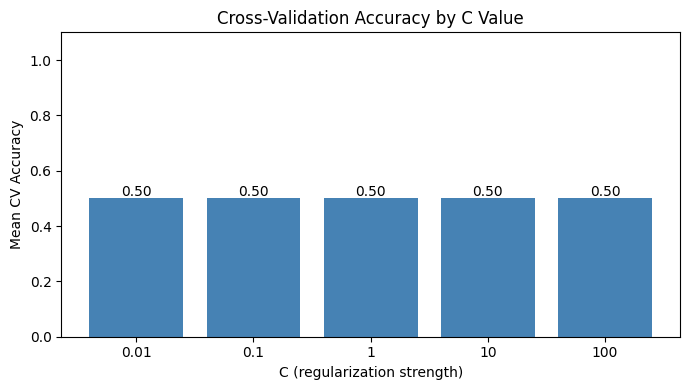


=== SENTIMENT PREDICTIONS ===
Review: 'This is honestly the best thing I've bought all year'
 -> Predicted: [NEGATIVE]

Review: 'It stopped working after one week, very frustrating'
 -> Predicted: [NEGATIVE]



In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

# 1. Dataset (with a few noisy/ambiguous reviews mixed in on purpose)
reviews = [
    "This product is amazing, exceeded all my expectations",
    "Absolutely love it, best purchase I made this year",
    "Great quality and fast shipping, very happy",
    "Terrible experience, broke after two days of use",
    "Waste of money, does not work as advertised",
    "Very disappointed, customer service was unhelpful",
    "It's okay I guess, works but nothing special",       # ambiguous/noisy
    "Not bad, but I expected a bit more for the price",   # ambiguous/noisy
    "Decent product overall, does the job fine"
]
sentiments = [
    "positive", "positive", "positive",
    "negative", "negative", "negative",
    "negative", "negative", "positive"
]

# 2. Train/test split
# Rationale: never evaluate on the same data you trained on,
# otherwise accuracy looks great but means nothing
X_train, X_test, y_train, y_test = train_test_split(
    reviews, sentiments,
    test_size=0.3,
    random_state=42
)

# 3. Pipeline definition
# tfidf converts text to sparse numeric vectors
# svm with a linear kernel + soft margin (C controls tolerance for noisy points)
review_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english')),
    ('svm', SVC(kernel='linear', C=1.0))
])

# 4. Fit model
review_pipeline.fit(X_train, y_train)

# 5. Evaluate on held-out test data
y_pred = review_pipeline.predict(X_test)
print("=== CLASSIFICATION REPORT (C=1.0) ===")
print(classification_report(y_test, y_pred))

# 6. Tune C properly instead of guessing
# Rationale: low C = wider margin, more tolerant of noisy points (may underfit)
#            high C = narrow margin, tries to classify every point correctly (may overfit)
c_values = [0.01, 0.1, 1, 10, 100]
param_grid = {'svm__C': c_values}

grid_search = GridSearchCV(
    review_pipeline,
    param_grid,
    cv=3  # 3-fold cross-validation since the dataset is small
)
grid_search.fit(X_train, y_train)

print(f"\nBest C found: {grid_search.best_params_['svm__C']}")
print(f"Best cross-validation accuracy: {grid_search.best_score_:.2f}")

# 7. Simple chart: accuracy score for each C value tested
# Rationale: quick visual to see which C generalizes best, not just the winner
cv_scores = grid_search.cv_results_['mean_test_score']

plt.figure(figsize=(7, 4))
bars = plt.bar([str(c) for c in c_values], cv_scores, color='steelblue')

# Add value labels on top of each bar
for bar, score in zip(bars, cv_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{score:.2f}",
        ha='center'
    )

plt.title("Cross-Validation Accuracy by C Value")
plt.xlabel("C (regularization strength)")
plt.ylabel("Mean CV Accuracy")
plt.ylim(0, 1.1)
plt.tight_layout()
plt.show()

# 8. Predict incoming unseen reviews using the best model
incoming_reviews = [
    "This is honestly the best thing I've bought all year",
    "It stopped working after one week, very frustrating"
]

best_model = grid_search.best_estimator_

print("\n=== SENTIMENT PREDICTIONS ===")
for review in incoming_reviews:
    sentiment = best_model.predict([review])[0]
    print(f"Review: '{review}'\n -> Predicted: [{sentiment.upper()}]\n")